In [1]:
import matplotlib.pyplot as plt
import pathlib 
import pandas as pd
import matplotlib.lines as mlines

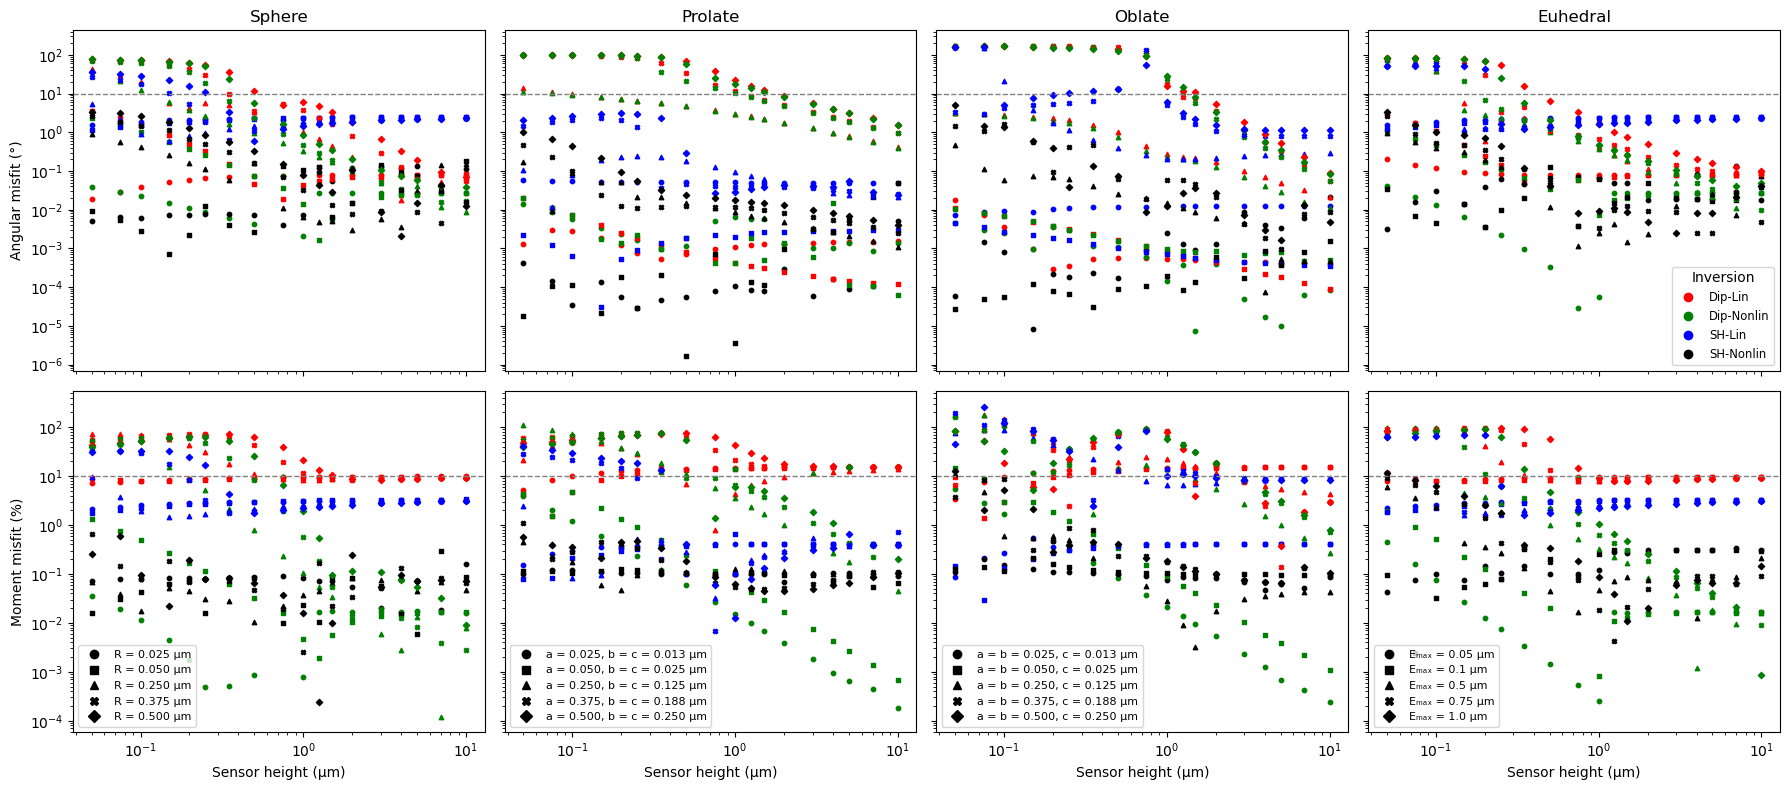

In [2]:
dataframe_dir = pathlib.Path("../../data/results")
results_df = pd.read_csv(dataframe_dir / "misfit_results.csv")
figure_dir= pathlib.Path("../../paper/figures")

# Atualiza para todos os modelos (incluindo novos)
all_models = sorted(results_df["model"].unique())
# Adiciona a geometria e dimensões
geometry_data = {
    "model": [f"eps{i}" for i in range(20)],
    "shape": ["Sphere"] * 5 + ["Prolate"] * 5 + ["Oblate"] * 5 + ["Euhedral"] * 5,
    "a": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.025, 0.05, 0.25, 0.375, 0.5,
          0.025, 0.05, 0.25, 0.375, 0.5,
          None, None, None, None, None],
    "b": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          0.025, 0.05, 0.25, 0.375, 0.5,
          None, None, None, None, None],
    "c": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          None, None, None, None, None],
    "E_max": [None] * 15 + [0.05, 0.1, 0.5, 0.75, 1],
}
geometry_df = pd.DataFrame(geometry_data)
results_df = results_df.merge(geometry_df, on="model")

# Define marcadores
marker_list = ["o", "s", "^", "X", "D"]
marker_map = {}
label_map = {}

for idx, row in geometry_df.iterrows():
    model = row["model"]
    marker_map[model] = marker_list[idx % 5]
    if row["shape"] == "Sphere":
        label = f"R = {row['a']:.3f} µm"
    elif row["shape"] == "Prolate":
        label = f"a = {row['a']:.3f}, b = c = {row['c']:.3f} µm"
    elif row["shape"] == "Oblate":
        label = f"a = b = {row['a']:.3f}, c = {row['c']:.3f} µm"
    elif row["shape"] == "Euhedral":
        label = f"Eₘₐₓ = {row['E_max']} µm"
    else:
        label = f"{model}"
    label_map[model] = label

# Misfit metrics
misfits = [
    ("angular_dipole_linear", "angular_dipole_nonlinear",
     "angular_multipole_linear", "angular_multipole_nonlinear", "Angular misfit (°)"),
    ("moment_misfit_dipole_linear", "moment_misfit_dipole_nonlinear",
     "moment_misfit_multipole_linear", "moment_misfit_multipole_nonlinear", "Moment misfit (%)"),
]

shapes = ["Sphere", "Prolate", "Oblate", "Euhedral"]
fig, axes = plt.subplots(len(misfits), len(shapes), figsize=(18, 8), sharex=True, sharey='row')

colors = ["red", "green", "blue", "black"]
methods = ["Dip-Lin", "Dip-Nonlin", "SH-Lin", "SH-Nonlin"]

for col, shape in enumerate(shapes):
    subset_shape = results_df[results_df["shape"] == shape]
    used_models = set()

    for row, (col1, col2, col3, col4, ylabel) in enumerate(misfits):
        ax = axes[row, col]
        for _, model_data in subset_shape.iterrows():
            model = model_data["model"]
            marker = marker_map[model]
            label = label_map[model] if model not in used_models else None
            used_models.add(model)

            for val, color in zip([col1, col2, col3, col4], colors):
                ax.scatter(
                    model_data["height_um"],
                    model_data[val],
                    color=color,
                    s=10,
                    marker=marker,
                    label=label if color == "red" else None  # evita duplicar
                )

        ax.axhline(10, color="gray", linestyle="--", linewidth=1)
        ax.set_yscale("log")
        ax.set_xscale("log")
        if row == len(misfits) - 1:
            ax.set_xlabel("Sensor height (µm)")
        if col == 0:
            ax.set_ylabel(ylabel)
        if row == 0:
            ax.set_title(shape)

    # Legenda de marcadores
    legend_ax = axes[-1, col]
    marker_handles = [
        mlines.Line2D([], [], color='black', marker=marker_map[model],
                      linestyle='None', label=label_map[model])
        for model in sorted(used_models, key=lambda m: int(m[3:]))
    ]
    legend_ax.legend(handles=marker_handles, fontsize=8, loc="lower left")

# Legenda geral de métodos
axes[0, -1].legend(
    handles=[
        mlines.Line2D([], [], color=colors[i], marker='o', linestyle='None', label=methods[i])
        for i in range(4)
    ],
    fontsize="small", loc="lower right", title="Inversion"
)

plt.tight_layout()
# plt.savefig(figure_dir / "model_comparison_with_micromag_model", dpi=300,
#             bbox_inches="tight", transparent=True)
plt.show()

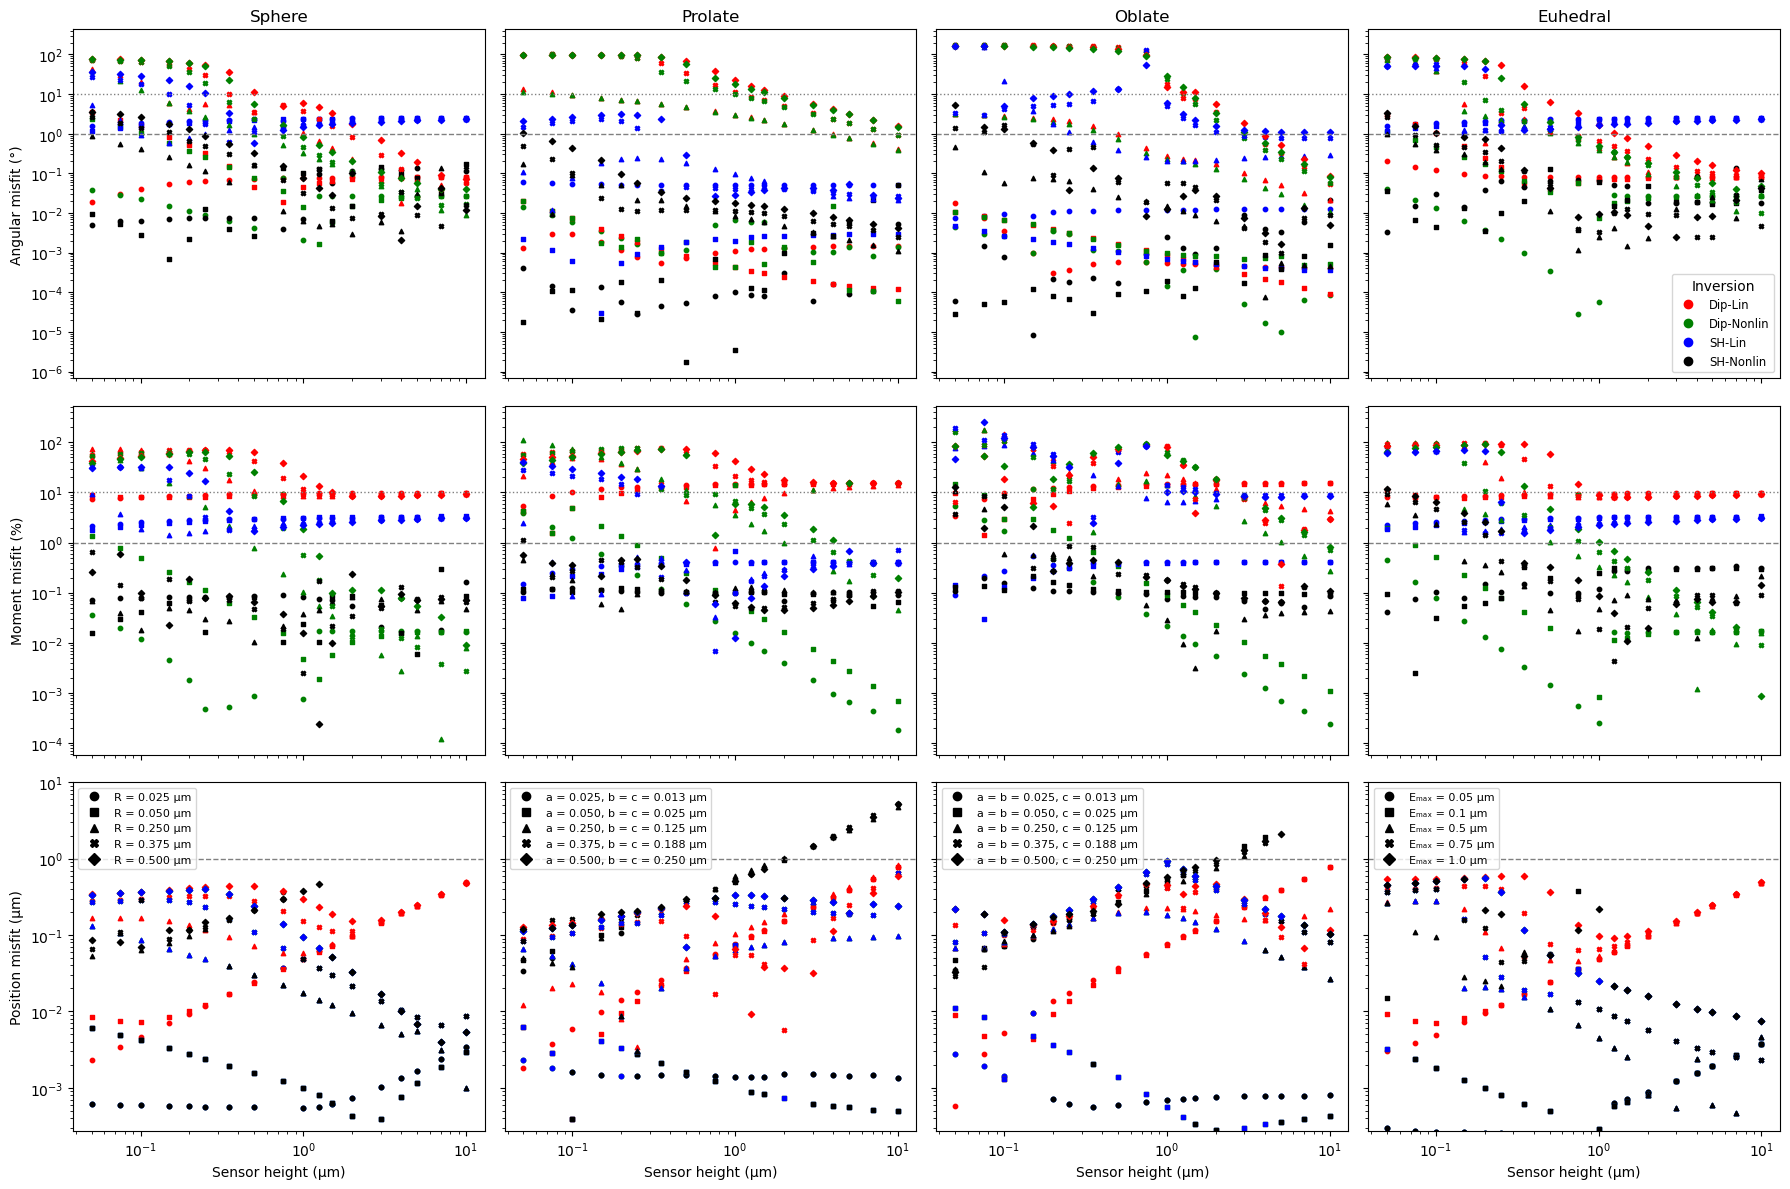

In [3]:
dataframe_dir = pathlib.Path("../../data/results")
results_df = pd.read_csv(dataframe_dir / "misfit_results.csv")
figure_dir= pathlib.Path("../../paper/figures")

# Atualiza para todos os modelos (incluindo novos)
all_models = sorted(results_df["model"].unique())

# Adiciona a geometria e dimensões
geometry_data = {
    "model": [f"eps{i}" for i in range(20)],
    "shape": ["Sphere"] * 5 + ["Prolate"] * 5 + ["Oblate"] * 5 + ["Euhedral"] * 5,
    "a": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.025, 0.05, 0.25, 0.375, 0.5,
          0.025, 0.05, 0.25, 0.375, 0.5,
          None, None, None, None, None],
    "b": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          0.025, 0.05, 0.25, 0.375, 0.5,
          None, None, None, None, None],
    "c": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          None, None, None, None, None],
    "E_max": [None] * 15 + [0.05, 0.1, 0.5, 0.75, 1],
}

geometry_df = pd.DataFrame(geometry_data)
results_df = results_df.merge(geometry_df, on="model")

# Define marcadores
marker_list = ["o", "s", "^", "X", "D"]
marker_map = {}
label_map = {}

for idx, row in geometry_df.iterrows():
    model = row["model"]
    marker_map[model] = marker_list[idx % 5]

    if row["shape"] == "Sphere":
        label = f"R = {row['a']:.3f} µm"
    elif row["shape"] == "Prolate":
        label = f"a = {row['a']:.3f}, b = c = {row['c']:.3f} µm"
    elif row["shape"] == "Oblate":
        label = f"a = b = {row['a']:.3f}, c = {row['c']:.3f} µm"
    elif row["shape"] == "Euhedral":
        label = f"Eₘₐₓ = {row['E_max']} µm"
    else:
        label = f"{model}"

    label_map[model] = label

# Misfit metrics (AGORA COM POSITION 🔥)
misfits = [
    ("angular_dipole_linear", "angular_dipole_nonlinear",
     "angular_multipole_linear", "angular_multipole_nonlinear", "Angular misfit (°)"),

    ("moment_misfit_dipole_linear", "moment_misfit_dipole_nonlinear",
     "moment_misfit_multipole_linear", "moment_misfit_multipole_nonlinear", "Moment misfit (%)"),

    ("position_misfit_dipole_linear", "position_misfit_dipole_nonlinear",
     "position_misfit_multipole_linear", "position_misfit_multipole_nonlinear", "Position misfit (µm)"),
]

shapes = ["Sphere", "Prolate", "Oblate", "Euhedral"]

# Aumenta altura da figura
fig, axes = plt.subplots(len(misfits), len(shapes),
                         figsize=(18, 12),
                         sharex=True, sharey='row')

colors = ["red", "green", "blue", "black"]
methods = ["Dip-Lin", "Dip-Nonlin", "SH-Lin", "SH-Nonlin"]

for col, shape in enumerate(shapes):
    subset_shape = results_df[results_df["shape"] == shape]
    used_models = set()

    for row, (col1, col2, col3, col4, ylabel) in enumerate(misfits):
        ax = axes[row, col]

        for _, model_data in subset_shape.iterrows():
            model = model_data["model"]
            marker = marker_map[model]
            label = label_map[model] if model not in used_models else None
            used_models.add(model)

            for val, color in zip([col1, col2, col3, col4], colors):
                ax.scatter(
                    model_data["height_um"],
                    model_data[val],
                    color=color,
                    s=10,
                    marker=marker,
                    label=label if color == "red" else None
                )

        

        # Escala Y: log para angular/moment, linear para position
        if "Position" in ylabel:
            ax.set_yscale("log")
            ax.set_ylim(None, 1.0e1)
            ax.axhline(1, color="gray", linestyle="--", linewidth=1)
        else:
            ax.set_yscale("log")
            ax.axhline(10, color="gray", linestyle=":", linewidth=1)
            ax.axhline(1, color="gray", linestyle="--", linewidth=1)
            

        ax.set_xscale("log")

        if row == len(misfits) - 1:
            ax.set_xlabel("Sensor height (µm)")
        if col == 0:
            ax.set_ylabel(ylabel)
        if row == 0:
            ax.set_title(shape)

    # Legenda de marcadores
    legend_ax = axes[-1, col]
    marker_handles = [
        mlines.Line2D([], [], color='black',
                      marker=marker_map[model],
                      linestyle='None',
                      label=label_map[model])
        for model in sorted(used_models, key=lambda m: int(m[3:]))
    ]

    legend_ax.legend(handles=marker_handles, fontsize=8, loc="upper left")

# Legenda geral de métodos
axes[0, -1].legend(
    handles=[
        mlines.Line2D([], [], color=colors[i],
                      marker='o',
                      linestyle='None',
                      label=methods[i])
        for i in range(4)
    ],
    fontsize="small",
    loc="lower right",
    title="Inversion"
)

plt.tight_layout()
plt.savefig(figure_dir / "model_comparison_with_micromag_model", dpi=300,
            bbox_inches="tight", transparent=True)

plt.show()

# Full comparison for supplementary figure

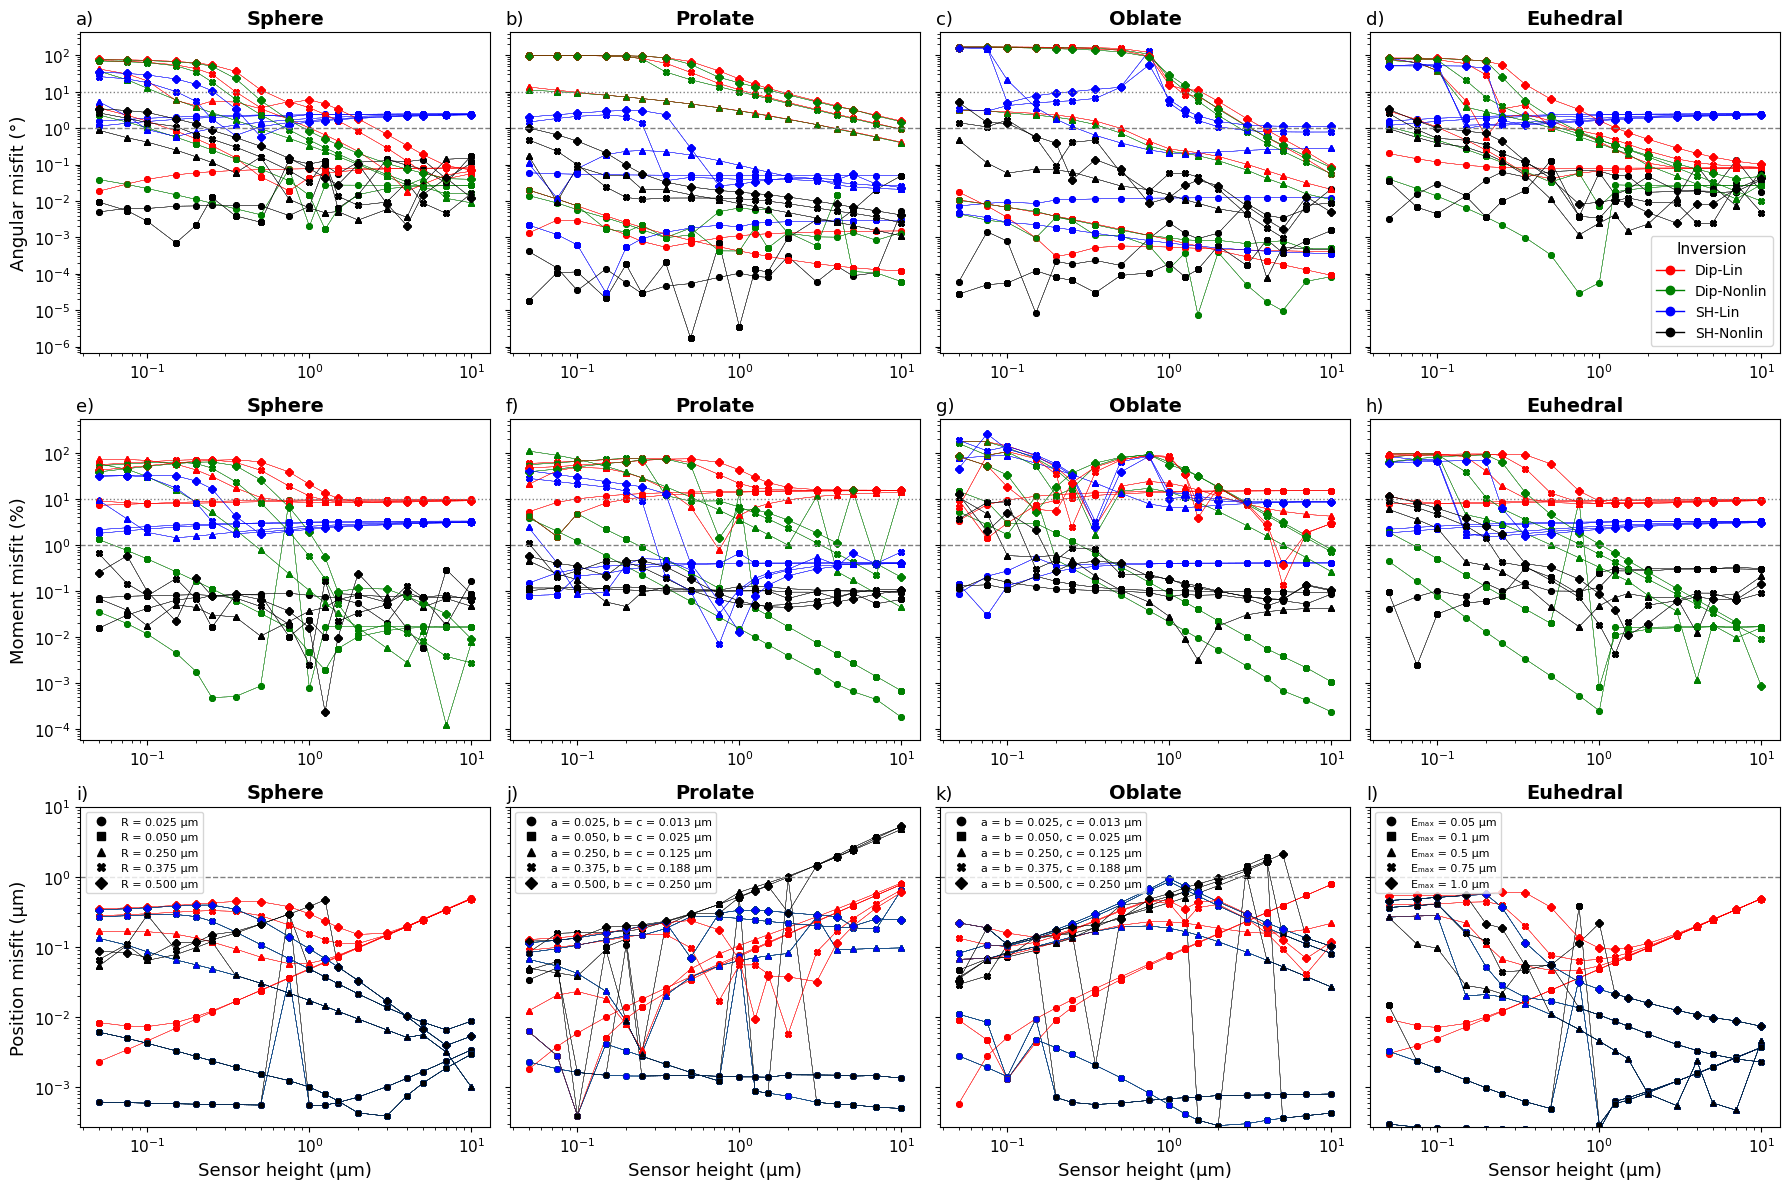

In [4]:
dataframe_dir = pathlib.Path("../../data/results")
results_df = pd.read_csv(dataframe_dir / "misfit_results.csv")
figure_dir = pathlib.Path("../../paper/figures")

# Update for all models (including new ones)
all_models = sorted(results_df["model"].unique())

# Add geometry and dimensions
geometry_data = {
    "model": [f"eps{i}" for i in range(20)],
    "shape": ["Sphere"] * 5 + ["Prolate"] * 5 + ["Oblate"] * 5 + ["Euhedral"] * 5,
    "a": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.025, 0.05, 0.25, 0.375, 0.5,
          0.025, 0.05, 0.25, 0.375, 0.5,
          None, None, None, None, None],
    "b": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          0.025, 0.05, 0.25, 0.375, 0.5,
          None, None, None, None, None],
    "c": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          None, None, None, None, None],
    "E_max": [None] * 15 + [0.05, 0.1, 0.5, 0.75, 1],
}

geometry_df = pd.DataFrame(geometry_data)
results_df = results_df.merge(geometry_df, on="model")

# Define markers (all 5 sizes included for the supplementary section)
marker_list = ["o", "s", "^", "X", "D"]
marker_map = {}
label_map = {}

for idx, row in geometry_df.iterrows():
    model = row["model"]
    marker_map[model] = marker_list[idx % 5]

    if row["shape"] == "Sphere":
        label = f"R = {row['a']:.3f} µm"
    elif row["shape"] == "Prolate":
        label = f"a = {row['a']:.3f}, b = c = {row['c']:.3f} µm"
    elif row["shape"] == "Oblate":
        label = f"a = b = {row['a']:.3f}, c = {row['c']:.3f} µm"
    elif row["shape"] == "Euhedral":
        label = f"Eₘₐₓ = {row['E_max']} µm"
    else:
        label = f"{model}"

    label_map[model] = label

# Misfit metrics (complete set with position)
misfits = [
    ("angular_dipole_linear", "angular_dipole_nonlinear",
     "angular_multipole_linear", "angular_multipole_nonlinear", "Angular misfit (°)"),

    ("moment_misfit_dipole_linear", "moment_misfit_dipole_nonlinear",
     "moment_misfit_multipole_linear", "moment_misfit_multipole_nonlinear", "Moment misfit (%)"),

    ("position_misfit_dipole_linear", "position_misfit_dipole_nonlinear",
     "position_misfit_multipole_linear", "position_misfit_multipole_nonlinear", "Position misfit (µm)"),
]

shapes = ["Sphere", "Prolate", "Oblate", "Euhedral"]

# Increase figure height to accommodate the layout nicely
fig, axes = plt.subplots(len(misfits), len(shapes),
                         figsize=(18, 12),
                         sharex=False, sharey='row')

colors = ["red", "green", "blue", "black"]
methods = ["Dip-Lin", "Dip-Nonlin", "SH-Lin", "SH-Nonlin"]

for col, shape in enumerate(shapes):
    subset_shape = results_df[results_df["shape"] == shape]
    used_models = set()

    for row, (col1, col2, col3, col4, ylabel) in enumerate(misfits):
        ax = axes[row, col]

        for _, model_data in subset_shape.iterrows():
            model = model_data["model"]
            marker = marker_map[model]
            label = label_map[model] if model not in used_models else None
            used_models.add(model)

            # Retrieve the full height array and misfit array for this model sorted by height
            curve_data = subset_shape[subset_shape["model"] == model].sort_values("height_um")
            x_vals = curve_data["height_um"]

            for val, color in zip([col1, col2, col3, col4], colors):
                y_vals = curve_data[val]

                # Plot thin connecting lines with transparency across sensor heights
                ax.plot(
                    x_vals, y_vals,
                    color=color,
                    linestyle='-',
                    linewidth=0.25,
                    alpha=0.15,
                    zorder=1
                )

                # Plot markers on top of the lines for specific data points
                ax.scatter(
                    x_vals, y_vals,
                    color=color,
                    s=12,
                    marker=marker,
                    label=label if color == "red" else None,
                    zorder=2
                )

        # Y-axis scale: log for angular/moment and position
        if "Position" in ylabel:
            ax.set_yscale("log")
            ax.set_ylim(None, 1.0e1)
            ax.axhline(1, color="gray", linestyle="--", linewidth=1)
        else:
            ax.set_yscale("log")
            ax.axhline(10, color="gray", linestyle=":", linewidth=1)
            ax.axhline(1, color="gray", linestyle="--", linewidth=1)

        ax.set_xscale("log")

        # Increase tick label font size for better readability
        ax.tick_params(axis='both', which='major', labelsize=11)

        # Set labels and titles with larger font sizes
        if row == len(misfits) - 1:
            ax.set_xlabel("Sensor height (µm)", fontsize=13)
        if col == 0:
            ax.set_ylabel(ylabel, fontsize=13)
        # if row == 0:
        ax.set_title(shape, fontsize=14, fontweight='bold')

    # Marker legend for each column with adjusted font size
    legend_ax = axes[-1, col]
    marker_handles = [
        mlines.Line2D([], [], color='black',
                      marker=marker_map[model],
                      linestyle='None',
                      label=label_map[model])
        for model in sorted(used_models, key=lambda m: int(m[3:]))
    ]

    legend_ax.legend(handles=marker_handles, fontsize=8, loc="upper left", framealpha=0.8)

# General method legend on the top-right subplot with adjusted font size
axes[0, -1].legend(
    handles=[
        mlines.Line2D([], [], color=colors[i],
                      marker='o',
                      linestyle='-',
                      linewidth=1,
                      label=methods[i])
        for i in range(4)
    ],
    fontsize=10,
    loc="lower right",
    title="Inversion",
    title_fontsize=11,
    framealpha=0.8
)
for ax, letter in zip(axes.ravel(), "a b c d e f g h i j k l".split()):
    ax.text(-0.01, 1.025, f"{letter})", transform=ax.transAxes, fontsize=13)

plt.tight_layout()

plt.savefig(figure_dir / "model_comparison_supplementary.png", dpi=300,
            bbox_inches="tight", transparent=True)

plt.show()

# Simplified comparison (mid-term sizes removed)

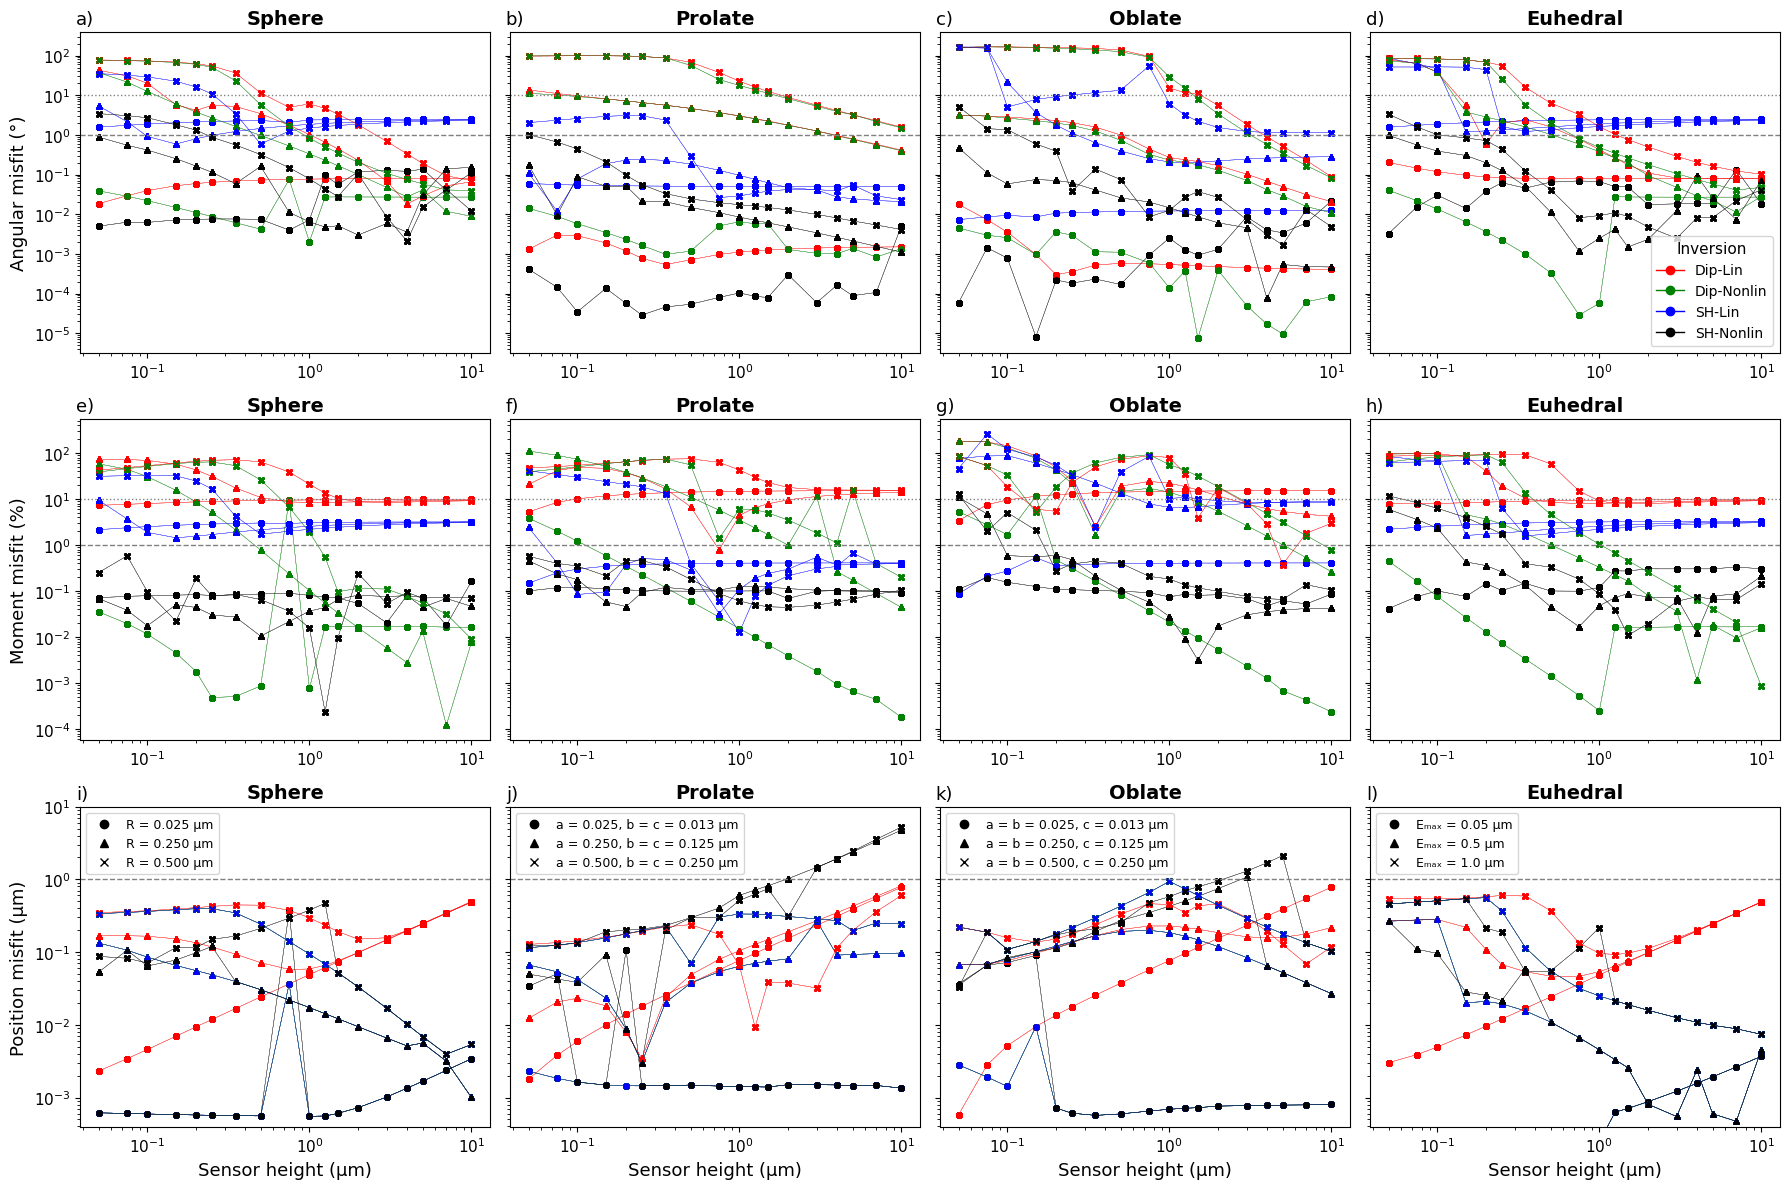

In [5]:
dataframe_dir = pathlib.Path("../../data/results")
results_df = pd.read_csv(dataframe_dir / "misfit_results.csv")
figure_dir = pathlib.Path("../../paper/figures")

# Update for all models (including new ones)
all_models = sorted(results_df["model"].unique())

# Add geometry and dimensions
geometry_data = {
    "model": [f"eps{i}" for i in range(20)],
    "shape": ["Sphere"] * 5 + ["Prolate"] * 5 + ["Oblate"] * 5 + ["Euhedral"] * 5,
    "a": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.025, 0.05, 0.25, 0.375, 0.5,
          0.025, 0.05, 0.25, 0.375, 0.5,
          None, None, None, None, None],
    "b": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          0.025, 0.05, 0.25, 0.375, 0.5,
          None, None, None, None, None],
    "c": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          None, None, None, None, None],
    "E_max": [None] * 15 + [0.05, 0.1, 0.5, 0.75, 1],
}

geometry_df = pd.DataFrame(geometry_data)
results_df = results_df.merge(geometry_df, on="model")

# Filter to keep only 3 sizes per shape (index 0: smallest, 2: medium, 4: largest)
selected_models = []
for shape in ["Sphere", "Prolate", "Oblate", "Euhedral"]:
    shape_models = geometry_df[geometry_df["shape"] == shape]["model"].values
    selected_models.extend([shape_models[0], shape_models[2], shape_models[4]])

results_df = results_df[results_df["model"].isin(selected_models)]
geometry_df = geometry_df[geometry_df["model"].isin(selected_models)]

# Define markers (now only 3 markers for 3 sizes)
marker_list = ["o", "^", "x"]
marker_map = {}
label_map = {}

# Group by shape to assign markers properly for the reduced set
for shape in ["Sphere", "Prolate", "Oblate", "Euhedral"]:
    shape_rows = geometry_df[geometry_df["shape"] == shape]
    for idx, (_, row) in enumerate(shape_rows.iterrows()):
        model = row["model"]
        marker_map[model] = marker_list[idx % len(marker_list)]

        if row["shape"] == "Sphere":
            label = f"R = {row['a']:.3f} µm"
        elif row["shape"] == "Prolate":
            label = f"a = {row['a']:.3f}, b = c = {row['c']:.3f} µm"
        elif row["shape"] == "Oblate":
            label = f"a = b = {row['a']:.3f}, c = {row['c']:.3f} µm"
        elif row["shape"] == "Euhedral":
            label = f"Eₘₐₓ = {row['E_max']} µm"
        else:
            label = f"{model}"

        label_map[model] = label

# Misfit metrics (including position)
misfits = [
    ("angular_dipole_linear", "angular_dipole_nonlinear",
     "angular_multipole_linear", "angular_multipole_nonlinear", "Angular misfit (°)"),

    ("moment_misfit_dipole_linear", "moment_misfit_dipole_nonlinear",
     "moment_misfit_multipole_linear", "moment_misfit_multipole_nonlinear", "Moment misfit (%)"),

    ("position_misfit_dipole_linear", "position_misfit_dipole_nonlinear",
     "position_misfit_multipole_linear", "position_misfit_multipole_nonlinear", "Position misfit (µm)"),
]

shapes = ["Sphere", "Prolate", "Oblate", "Euhedral"]

# Increase figure height to accommodate the layout nicely
fig, axes = plt.subplots(len(misfits), len(shapes),
                         figsize=(18, 12),
                         sharex=False, sharey='row')

colors = ["red", "green", "blue", "black"]
methods = ["Dip-Lin", "Dip-Nonlin", "SH-Lin", "SH-Nonlin"]

for col, shape in enumerate(shapes):
    subset_shape = results_df[results_df["shape"] == shape]
    used_models = set()

    for row, (col1, col2, col3, col4, ylabel) in enumerate(misfits):
        ax = axes[row, col]

        for _, model_data in subset_shape.iterrows():
            model = model_data["model"]
            marker = marker_map[model]
            label = label_map[model] if model not in used_models else None
            used_models.add(model)

            # Retrieve the full height array and misfit array for this model sorted by height
            curve_data = subset_shape[subset_shape["model"] == model].sort_values("height_um")
            x_vals = curve_data["height_um"]

            for val, color in zip([col1, col2, col3, col4], colors):
                y_vals = curve_data[val]

                # Plot connecting lines across sensor heights for this model
                ax.plot(
                    x_vals, y_vals,
                    color=color,
                    linestyle='-',
                    linewidth=0.25,
                    alpha=0.1,
                    zorder=1
                )

                # Plot markers on top of the lines for specific data points
                ax.scatter(
                    x_vals, y_vals,
                    color=color,
                    s=15,
                    marker=marker,
                    label=label if color == "red" else None,
                    zorder=2
                )

        # Y-axis scale: log for angular/moment and position
        if "Position" in ylabel:
            ax.set_yscale("log")
            ax.set_ylim(None, 1.0e1)
            ax.axhline(1, color="gray", linestyle="--", linewidth=1)
        else:
            ax.set_yscale("log")
            ax.axhline(10, color="gray", linestyle=":", linewidth=1)
            ax.axhline(1, color="gray", linestyle="--", linewidth=1)

        ax.set_xscale("log")

        # Increase tick label font size for better readability
        ax.tick_params(axis='both', which='major', labelsize=11)

        # Set labels and titles with larger font sizes
        if row == len(misfits) - 1:
            ax.set_xlabel("Sensor height (µm)", fontsize=13)
        if col == 0:
            ax.set_ylabel(ylabel, fontsize=13)
        # if row == 0:
        ax.set_title(shape, fontsize=14, fontweight='bold')

    # Marker legend for each column with adjusted font size
    legend_ax = axes[-1, col]
    marker_handles = [
        mlines.Line2D([], [], color='black',
                      marker=marker_map[model],
                      linestyle='None',
                      label=label_map[model])
        for model in sorted(used_models)
    ]

    legend_ax.legend(handles=marker_handles, fontsize=9, loc="upper left", framealpha=0.8)

# General method legend on the top-right subplot with adjusted font size
axes[0, -1].legend(
    handles=[
        mlines.Line2D([], [], color=colors[i],
                      marker='o',
                      linestyle='-',
                      linewidth=1,
                      label=methods[i])
        for i in range(4)
    ],
    fontsize=10,
    loc="lower right",
    title="Inversion",
    title_fontsize=11,
    framealpha=0.8
)

plt.tight_layout()
# plt.savefig(figure_dir / "model_comparison_with_micromag_model.png", dpi=300,
#             bbox_inches="tight", transparent=True)

for ax, letter in zip(axes.ravel(), "a b c d e f g h i j k l".split()):
    ax.text(-0.01, 1.025, f"{letter})", transform=ax.transAxes, fontsize=13)

plt.show()

# Simplified comparison (mid-term sizes and linear dipolar model were removed)

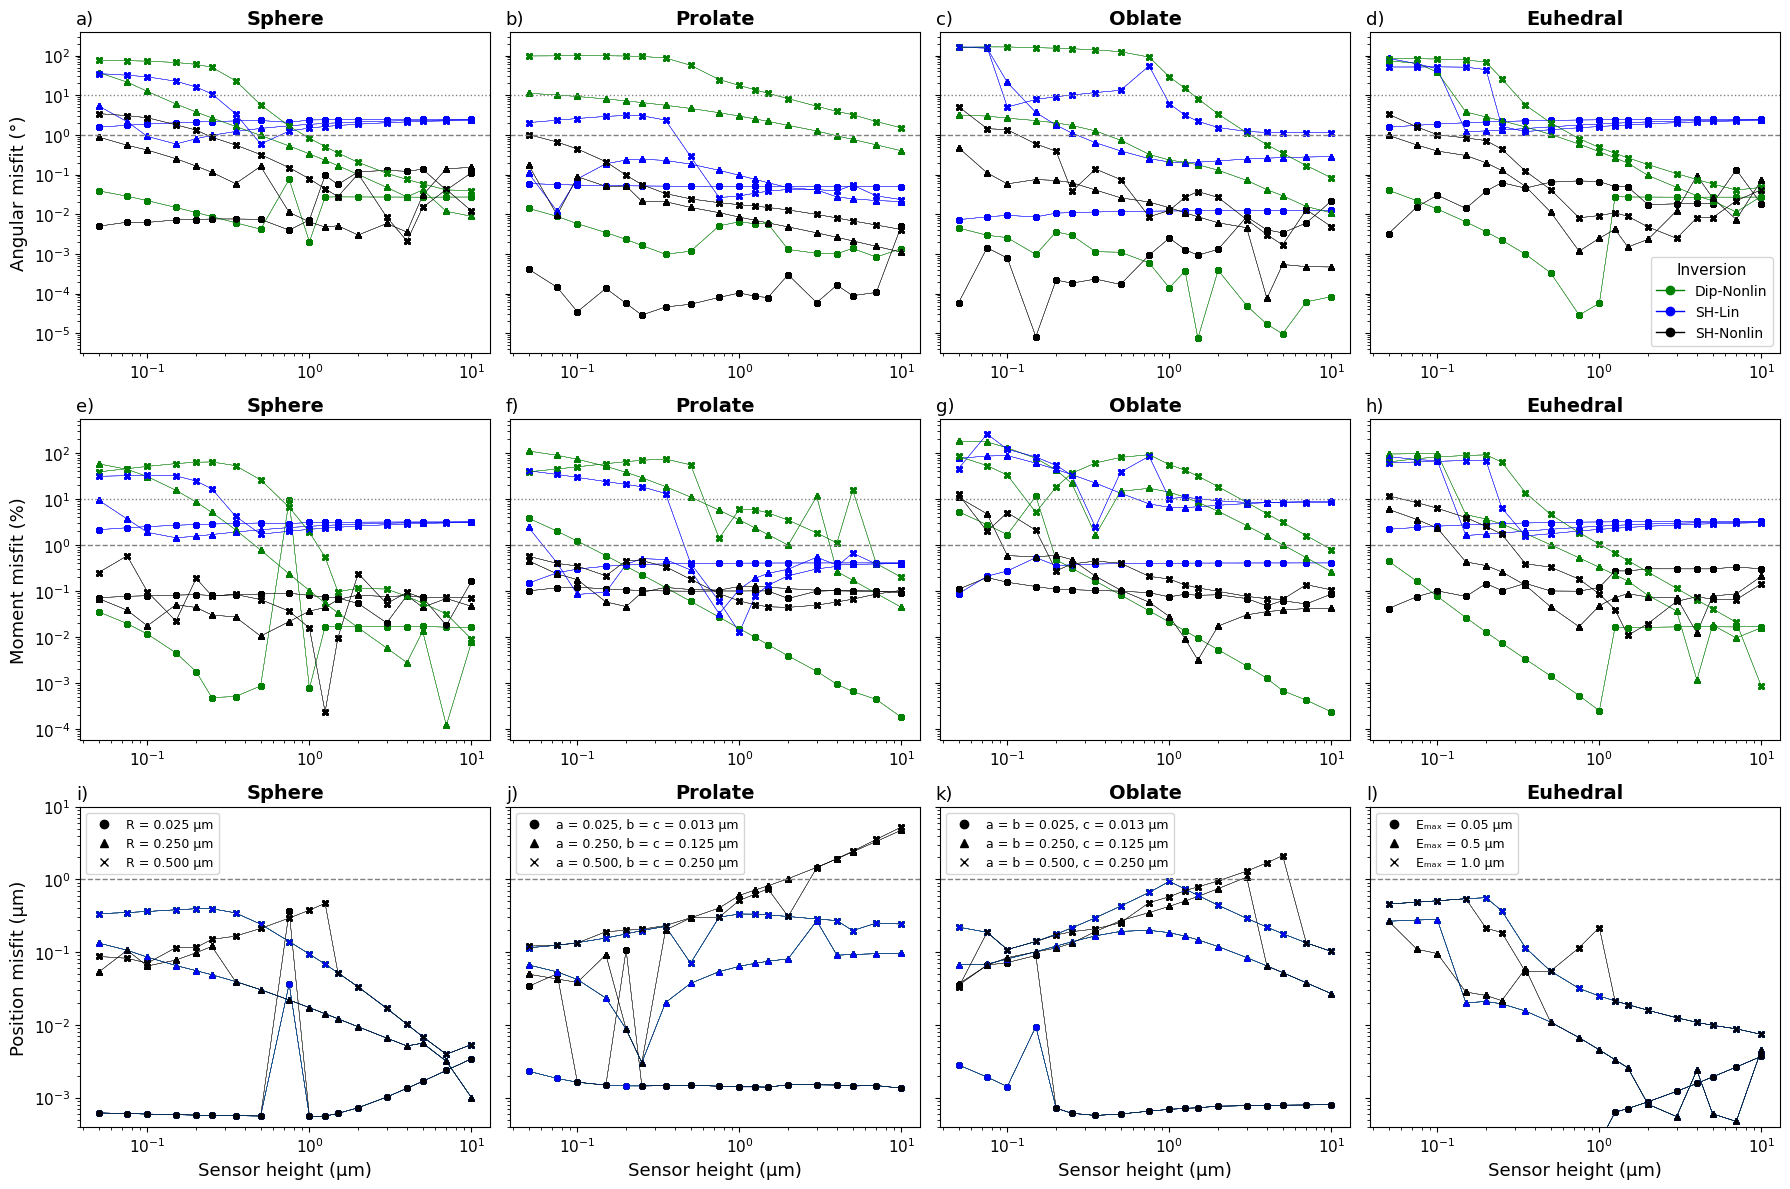

In [6]:
dataframe_dir = pathlib.Path("../../data/results")
results_df = pd.read_csv(dataframe_dir / "misfit_results.csv")
figure_dir = pathlib.Path("../../paper/figures")

# Update for all models (including new ones)
all_models = sorted(results_df["model"].unique())

# Add geometry and dimensions
geometry_data = {
    "model": [f"eps{i}" for i in range(20)],
    "shape": ["Sphere"] * 5 + ["Prolate"] * 5 + ["Oblate"] * 5 + ["Euhedral"] * 5,
    "a": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.025, 0.05, 0.25, 0.375, 0.5,
          0.025, 0.05, 0.25, 0.375, 0.5,
          None, None, None, None, None],
    "b": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          0.025, 0.05, 0.25, 0.375, 0.5,
          None, None, None, None, None],
    "c": [0.025, 0.05, 0.25, 0.375, 0.5,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          0.0125, 0.025, 0.125, 0.1875, 0.25,
          None, None, None, None, None],
    "E_max": [None] * 15 + [0.05, 0.1, 0.5, 0.75, 1],
}

geometry_df = pd.DataFrame(geometry_data)
results_df = results_df.merge(geometry_df, on="model")

# Filter to keep only 3 sizes per shape (index 0: smallest, 2: medium, 4: largest)
selected_models = []
for shape in ["Sphere", "Prolate", "Oblate", "Euhedral"]:
    shape_models = geometry_df[geometry_df["shape"] == shape]["model"].values
    selected_models.extend([shape_models[0], shape_models[2], shape_models[4]])

results_df = results_df[results_df["model"].isin(selected_models)]
geometry_df = geometry_df[geometry_df["model"].isin(selected_models)]

# Define markers (now only 3 markers for 3 sizes)
marker_list = ["o", "^", "x"]
marker_map = {}
label_map = {}

# Group by shape to assign markers properly for the reduced set
for shape in ["Sphere", "Prolate", "Oblate", "Euhedral"]:
    shape_rows = geometry_df[geometry_df["shape"] == shape]
    for idx, (_, row) in enumerate(shape_rows.iterrows()):
        model = row["model"]
        marker_map[model] = marker_list[idx % len(marker_list)]

        if row["shape"] == "Sphere":
            label = f"R = {row['a']:.3f} µm"
        elif row["shape"] == "Prolate":
            label = f"a = {row['a']:.3f}, b = c = {row['c']:.3f} µm"
        elif row["shape"] == "Oblate":
            label = f"a = b = {row['a']:.3f}, c = {row['c']:.3f} µm"
        elif row["shape"] == "Euhedral":
            label = f"Eₘₐₓ = {row['E_max']} µm"
        else:
            label = f"{model}"

        label_map[model] = label

# Misfit metrics REMOVING the linear dipole model (keeping 3 methods instead of 4)
misfits = [
    ("angular_dipole_nonlinear",
     "angular_multipole_linear", "angular_multipole_nonlinear", "Angular misfit (°)"),

    ("moment_misfit_dipole_nonlinear",
     "moment_misfit_multipole_linear", "moment_misfit_multipole_nonlinear", "Moment misfit (%)"),

    ("position_misfit_dipole_nonlinear",
     "position_misfit_multipole_linear", "position_misfit_multipole_nonlinear", "Position misfit (µm)"),
]

shapes = ["Sphere", "Prolate", "Oblate", "Euhedral"]

# Increase figure height to accommodate the layout nicely
fig, axes = plt.subplots(len(misfits), len(shapes),
                         figsize=(18, 12),
                         sharex=False, sharey='row')

# 3 colors and methods now (excluding dipole linear)
colors = ["green", "blue", "black"]
methods = ["Dip-Nonlin", "SH-Lin", "SH-Nonlin"]

for col, shape in enumerate(shapes):
    subset_shape = results_df[results_df["shape"] == shape]
    used_models = set()

    for row, (col1, col2, col3, ylabel) in enumerate(misfits):
        ax = axes[row, col]

        for _, model_data in subset_shape.iterrows():
            model = model_data["model"]
            marker = marker_map[model]
            label = label_map[model] if model not in used_models else None
            used_models.add(model)

            # Retrieve the full height array and misfit array for this model sorted by height
            curve_data = subset_shape[subset_shape["model"] == model].sort_values("height_um")
            x_vals = curve_data["height_um"]

            for val, color in zip([col1, col2, col3], colors):
                y_vals = curve_data[val]

                # Plot connecting lines across sensor heights for this model
                ax.plot(
                    x_vals, y_vals,
                    color=color,
                    linestyle='-',
                    linewidth=0.25,
                    alpha=0.15,
                    zorder=1
                )

                # Plot markers on top of the lines for specific data points
                ax.scatter(
                    x_vals, y_vals,
                    color=color,
                    s=15,
                    marker=marker,
                    label=label if color == "green" else None,
                    zorder=2
                )

        # Y-axis scale: log for angular/moment and position
        if "Position" in ylabel:
            ax.set_yscale("log")
            ax.set_ylim(None, 1.0e1)
            ax.axhline(1, color="gray", linestyle="--", linewidth=1)
        else:
            ax.set_yscale("log")
            ax.axhline(10, color="gray", linestyle=":", linewidth=1)
            ax.axhline(1, color="gray", linestyle="--", linewidth=1)

        ax.set_xscale("log")

        # Increase tick label font size for better readability
        ax.tick_params(axis='both', which='major', labelsize=11)

        # Set labels and titles with larger font sizes
        if row == len(misfits) - 1:
            ax.set_xlabel("Sensor height (µm)", fontsize=13)
        if col == 0:
            ax.set_ylabel(ylabel, fontsize=13)
        
        ax.set_title(shape, fontsize=14, fontweight='bold')

    # Marker legend for each column with adjusted font size
    legend_ax = axes[-1, col]
    marker_handles = [
        mlines.Line2D([], [], color='black',
                      marker=marker_map[model],
                      linestyle='None',
                      label=label_map[model])
        for model in sorted(used_models)
    ]

    legend_ax.legend(handles=marker_handles, fontsize=9, loc="upper left", framealpha=0.8)

# General method legend on the top-right subplot with adjusted font size
axes[0, -1].legend(
    handles=[
        mlines.Line2D([], [], color=colors[i],
                      marker='o',
                      linestyle='-',
                      linewidth=1,
                      label=methods[i])
        for i in range(3)
    ],
    fontsize=10,
    loc="lower right",
    title="Inversion",
    title_fontsize=11,
    framealpha=0.8
)

plt.tight_layout()
plt.savefig(figure_dir / "model_comparison_with_micromag_model.png", dpi=300,
            bbox_inches="tight", transparent=True)

for ax, letter in zip(axes.ravel(), "a b c d e f g h i j k l".split()):
    ax.text(-0.01, 1.025, f"{letter})", transform=ax.transAxes, fontsize=13)

plt.show()